# Gaussian Process Regression

*Predictions that know when they are guessing.*



:::{admonition} What this lecture is about
:class: tip
Every regression model so far has handed us a **single answer**. If you ask it for the hardness of a new alloy, it will give you one number.

But it never told us one very important thing: **how sure is it?**

Now imagine you trained a model on five alloys and you ask it to predict the hardness of a *sixth* - one whose composition sits far from anything it has seen. The model will still cheerfully give you a number. But should you trust it as much as a prediction sitting right next to your training data?

Of course not! And yet a normal regression model **says the same thing either way**. It has no way to whisper "I'm confident here" or "honestly, I'm guessing there." 🤷‍♂️ 
:::

:::{admonition} The gap we want to fill
:class: important
We want a model that returns **two things**: a best guess, *and* how much to trust it.

Near the data → be confident.
Far from the data → admit the doubt.
:::

Gaussian Process Regression (GPR) tries to fix that. It gives a prediction **and** an honest measure of doubt - error bars that grow wherever we have little data. In materials science, where every experiment costs time and money, knowing *where the model is unsure* is worth a lot.


Here is the same handful of points, drawn two ways. On the left, the old way: one curve, one answer everywhere. On the right, GPR: the answer comes wrapped in a band that **widens where there is no data**.

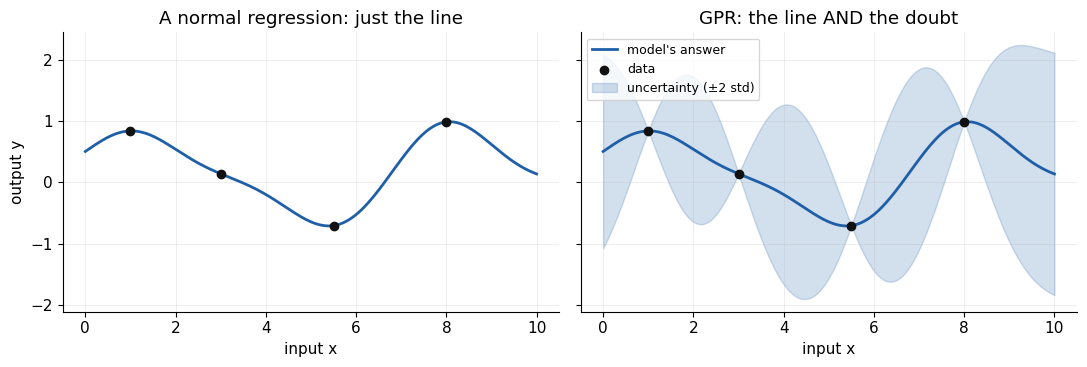

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C, WhiteKernel

plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "grid.linewidth": 0.6})
DATA_C, MEAN_C, BAND_C, SAMP_C, TRUE_C = "#111111","#1f5fa8","#1f5fa8","#8a8a8a","#c44e52"

# a few sparse measurements of a smooth (illustrative) function
X_train = np.array([1.0, 3.0, 5.5, 8.0]).reshape(-1, 1)
y_train = np.sin(X_train).ravel()
X_grid  = np.linspace(0, 10, 300).reshape(-1, 1)

gp = GaussianProcessRegressor(kernel=C(1.0)*RBF(1.0), alpha=1e-4, optimizer=None)
gp.fit(X_train, y_train)
mean, std = gp.predict(X_grid, return_std=True)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax in (axL, axR):
    ax.plot(X_grid, mean, color=MEAN_C, lw=2, label="model's answer")
    ax.scatter(X_train, y_train, color=DATA_C, zorder=5, label="data")
    ax.set_xlabel("input x")
axL.set_title("A normal regression: just the line")
axR.fill_between(X_grid.ravel(), mean-2*std, mean+2*std, color=BAND_C,
                 alpha=0.20, label="uncertainty (\u00b12 std)")
axR.set_title("GPR: the line AND the doubt")
axL.set_ylabel("output y"); axR.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()


Look at the right panel. Right on top of a data point, the band is thin - the model is sure. In the gaps in-between datapoints, the band balloons out - there's a range of possibilities - the model is telling you, honestly, that it is guessing.🤔

## The big switch: from one curve to a cloud of curves

How does GPR work this way? 

Old thinking: *"Find the one best curve."*

GPR thinking: *"Consider **every** smooth curve that could fit through the data, and keep track of all of them at once."*

That sounds impossible - there are infinitely many curves. The clever trick of a **Gaussian Process** is a compact way to describe this whole family using only the Normal (Gaussian) distribution you already met in the statistics chapters. 

Let's think of it this way, before we show it any data, the GP already has opinions. It believes the true function is probably **smooth** - no wild jumps. So the family of curves it considers all look reasonably smooth. Here are a few of them, drawn at random:

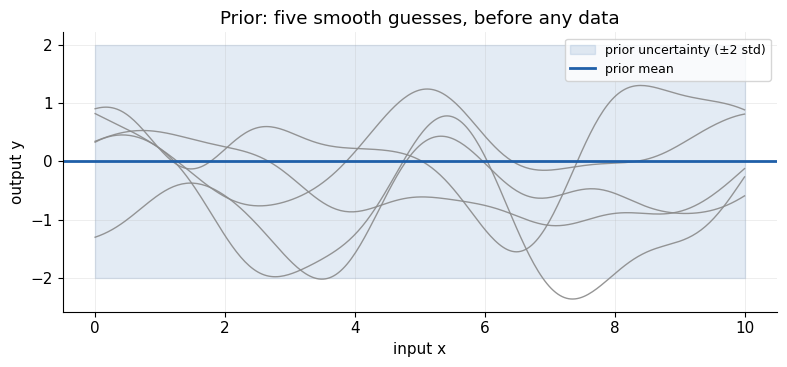

In [2]:
# The GP prior: smooth curves BEFORE seeing any data
kernel = C(1.0)*RBF(length_scale=1.0)
K = kernel(X_grid) + 1e-9*np.eye(len(X_grid))
L = np.linalg.cholesky(K)
rng = np.random.default_rng(1)
prior_curves = L @ rng.standard_normal((len(X_grid), 5))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.fill_between(X_grid.ravel(), -2, 2, color=BAND_C, alpha=0.12,
                label="prior uncertainty (\u00b12 std)")
ax.plot(X_grid, prior_curves, color=SAMP_C, lw=1, alpha=0.9)
ax.axhline(0, color=MEAN_C, lw=2, label="prior mean")
ax.set_xlabel("input x"); ax.set_ylabel("output y")
ax.set_title("Prior: five smooth guesses, before any data")
ax.legend(loc="upper right", fontsize=9); plt.tight_layout(); plt.show()


These are **prior** samples - the model's imagination *before* any data. Notice: they are all smooth, they wander around, and the shaded band shows how far they can stray. No single answer yet; just a cloud of possibilities.

## Feeding in the data

Now we show the GP a few real measurements. Think of each data point as a **nail** hammered into the page 🔨. The cloud of curves must now pass **through (or very near) every nail**.

Watch what happens:

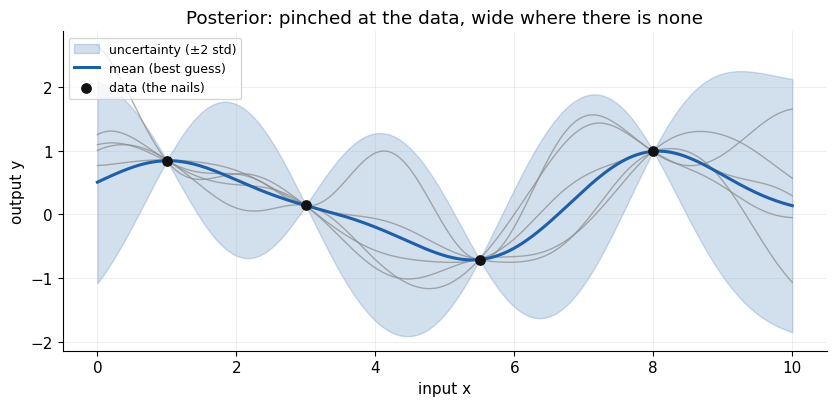

In [3]:
# The GP posterior: the same curves, now pinned to the data
X_train = np.array([1.0, 3.0, 5.5, 8.0]).reshape(-1, 1)
y_train = np.sin(X_train).ravel()
gp = GaussianProcessRegressor(kernel=C(1.0)*RBF(1.0), alpha=1e-4, optimizer=None)
gp.fit(X_train, y_train)
mean, std = gp.predict(X_grid, return_std=True)
post_curves = gp.sample_y(X_grid, 5, random_state=2)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.fill_between(X_grid.ravel(), mean-2*std, mean+2*std, color=BAND_C,
                alpha=0.20, label="uncertainty (\u00b12 std)")
ax.plot(X_grid, post_curves, color=SAMP_C, lw=1, alpha=0.7)
ax.plot(X_grid, mean, color=MEAN_C, lw=2.2, label="mean (best guess)")
ax.scatter(X_train, y_train, color=DATA_C, zorder=5, s=45, label="data (the nails)")
ax.set_xlabel("input x"); ax.set_ylabel("output y")
ax.set_title("Posterior: pinched at the data, wide where there is none")
ax.legend(loc="upper left", fontsize=9); plt.tight_layout(); plt.show()


- At each nail (data point), all the curves are forced together, so the band **pinches almost to a single point**. The model is confident there.
- In the gaps between nails, the curves are freer to wiggle, so the band **fans out**. Less data, more doubt.
- Far past the last nail, the curves scatter completely and the band is **widest**. The model knows it is extrapolating.

The thick line is the **average** of all these curves - that is GPR's best guess (the *posterior mean*). The shaded band is the spread - that is its *uncertainty*. You get both, at every input 🥳.

:::{note} Two words worth noting
- **Prior** = the cloud of curves *before* data (the wanderers).
- **Posterior** = the cloud *after* data (pinched at the nails).

GPR's whole job is to turn the prior into the posterior once it sees your measurements.
:::

## The kernel: what does "close" mean?

We keep saying the GP prefers *smooth* curves. But how smooth? That is decided by the **kernel** (also called the covariance function).

A kernel is just a rule: **the closer two inputs are, the more their outputs should agree.** Two alloys with almost the same composition should have almost the same hardness. Two very different alloys need not.

The kernel has a key setting called the **length-scale**. You can think of it as:

> *How far can I move along the x-axis before the trend stops being reliable?*

- **Short length-scale** → the model trusts only very nearby points → curves are wiggly, and uncertainty shoots up the moment you step away from data.
- **Long length-scale** → the model believes trends hold over a wide range → curves are smooth, and it stays confident across bigger gaps.

Same data, three different length-scales:

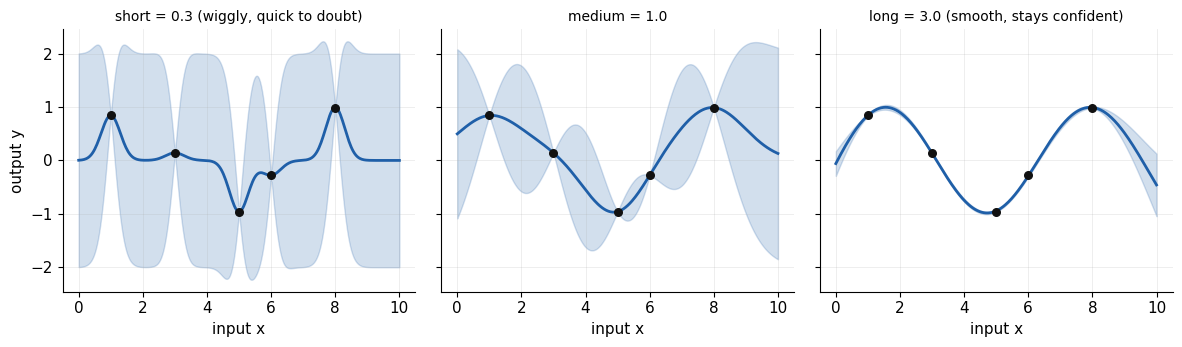

In [4]:
# Same data, three length-scales
X_train = np.array([1.0, 3.0, 5.0, 6.0, 8.0]).reshape(-1, 1)
y_train = np.sin(X_train).ravel()
length_scales = [0.3, 1.0, 3.0]
labels = ["short = 0.3 (wiggly, quick to doubt)",
          "medium = 1.0",
          "long = 3.0 (smooth, stays confident)"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, ls, lab in zip(axes, length_scales, labels):
    g = GaussianProcessRegressor(kernel=C(1.0)*RBF(ls), alpha=1e-4, optimizer=None)
    g.fit(X_train, y_train)
    m, s = g.predict(X_grid, return_std=True)
    ax.fill_between(X_grid.ravel(), m-2*s, m+2*s, color=BAND_C, alpha=0.20)
    ax.plot(X_grid, m, color=MEAN_C, lw=2)
    ax.scatter(X_train, y_train, color=DATA_C, zorder=5, s=30)
    ax.set_title(lab, fontsize=10); ax.set_xlabel("input x")
axes[0].set_ylabel("output y"); plt.tight_layout(); plt.show()


Choosing the length-scale is like choosing how far to trust a pattern. Too short and the model is jumpy and never confident. Too long and it may smooth over real detail. The good news: GPR can **tune this for you** automatically.

## The Bayesian thread

The Bayesian thread refers to the continuous line running through - the *prior → posterior* story:

1. **Prior:** before data, believe the function is some smooth thing (the cloud of wanderers).
2. **Data:** observe a few points (the nails).
3. **Posterior:** update the belief to keep only curves that fit the data (the pinched cloud).

**start with a belief, see evidence, update the belief.** GPR does it not over a few numbers, but over *whole functions*. You will meet the same idea again in the Bayesian Optimization.


Remember at the end of the last chapter, we mentioned that Ridge and Lasso have a hidden **Bayesian** side?

The Ridge penalty is really a **belief**. Before seeing any data, Ridge assumes the coefficients are probably small: a bell-shaped (Gaussian) prior centred on zero. After seeing the data, Ridge reports the *single most probable* set of coefficients under that belief. The penalty strength λ is the ratio of noise variance to prior variance, so a large λ means "I strongly believe the coefficients are near zero". (Lasso does the same with a sharper, spiky prior, which is why it can set coefficients exactly to zero.)

But Ridge keeps only the peak of the belief and throws away the spread. **GPR keeps the whole thing.** It runs the same *prior → posterior* recipe.

The two methods meet exactly: a GP with a *linear* kernel has a posterior mean identical to the Ridge prediction. The GP adds the error bars that Ridge cannot give.


## Using GPR in practice

Here is the good news for coders: `scikit-learn` hides all the maths. The pattern is the same `fit` / `predict` you already know - with **one extra flag** that unlocks the uncertainty.

Kernel that sklearn tuned for us: 1.16**2 * RBF(length_scale=1.62) + WhiteKernel(noise_level=1.31e-07)
x =  5.0:  prediction = -0.895   uncertainty (std) = 0.000
x =  9.5:  prediction = +0.617   uncertainty (std) = 0.629


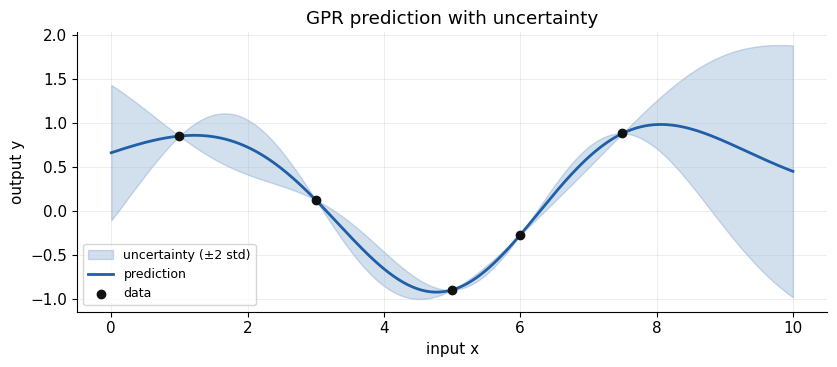

In [5]:
import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel

# 1) a small, made-up dataset (illustrative only)
rng = np.random.default_rng(0)
X_train = np.array([1.0, 3.0, 5.0, 6.0, 7.5]).reshape(-1, 1)
y_train = np.sin(X_train).ravel() + 0.1 * rng.standard_normal(len(X_train))

# 2) build a kernel: overall scale x smoothness (+ a little noise)
kernel = ConstantKernel(1.0) * RBF(length_scale=1.0) + WhiteKernel(0.01, (1e-8, 1e1))

# 3) fit -- scikit-learn tunes the kernel settings for you
gpr = GaussianProcessRegressor(kernel=kernel, normalize_y=True,
                               random_state=0, n_restarts_optimizer=5)
gpr.fit(X_train, y_train)
print("Kernel that sklearn tuned for us:", gpr.kernel_)

# 4) predict -- the magic flag is return_std=True
for xq in [5.0, 9.5]:               # one point NEAR data, one FAR away
    m, s = gpr.predict([[xq]], return_std=True)
    print(f"x = {xq:>4}:  prediction = {m[0]:+.3f}   uncertainty (std) = {s[0]:.3f}")

# a picture of the whole prediction with its uncertainty band
import matplotlib.pyplot as plt
Xg = np.linspace(0, 10, 300).reshape(-1, 1)
mean, std = gpr.predict(Xg, return_std=True)
plt.figure(figsize=(8.5, 3.8))
plt.fill_between(Xg.ravel(), mean-2*std, mean+2*std, alpha=0.20, color="#1f5fa8",
                 label="uncertainty (\u00b12 std)")
plt.plot(Xg, mean, color="#1f5fa8", lw=2, label="prediction")
plt.scatter(X_train, y_train, color="#111111", zorder=5, label="data")
plt.xlabel("input x"); plt.ylabel("output y"); plt.legend(fontsize=9)
plt.title("GPR prediction with uncertainty"); plt.tight_layout(); plt.show()


Two things to notice in the output above:

1. scikit-learn **tuned the length-scale itself**. It picked the kernel settings that best explain the data, by maximizing a score called the *marginal likelihood*. You did not have to guess.
2. The prediction **near** the data (x = 5.0) has a **tiny** uncertainty. The one **far** from data (x = 9.5) has a **large** one. 

:::{tip} The one flag to remember
`mean, std = gpr.predict(X, return_std=True)` gives you the uncertainty. Without `return_std=True`, GPR looks like any other regressor and you throw away its best feature.

(One naming note: in the previous chapter our regularization knob was `alpha`. In `GaussianProcessRegressor`, `alpha` means something different - a small **noise** term added to the data. Same word, new job.)
:::

## How GPR compares to what we've learned

| | Linear / Ridge / Lasso / Polynomial | **Gaussian Process Regression** |
|---|---|---|
| Output | one number | a number **+ an uncertainty** |
| Shape assumed | fixed (line, or fixed-degree curve) | flexible; no fixed shape (**non-parametric**) |
| Away from data | keeps marching along its line | mean drifts back to the prior, **band widens** (honest) |
| Main knob | penalty strength λ | the **kernel** and its length-scale |
| Cost | cheap, handles big data | heavier; best for **smaller** datasets |
| Best for | many samples, simple trend | **few, precious** samples where doubt matters |

That last row is why materials scientists love GPR. Experimental datasets are often **small and expensive** - exactly the case where GPR shines, and where knowing the uncertainty changes what you do next.

## Why this matters: choosing the next experiment

Suppose you have measured a property for a few compositions, but there is a **gap** you have not explored. GPR will predict across the gap - and honestly flag it as the region of **highest uncertainty**.

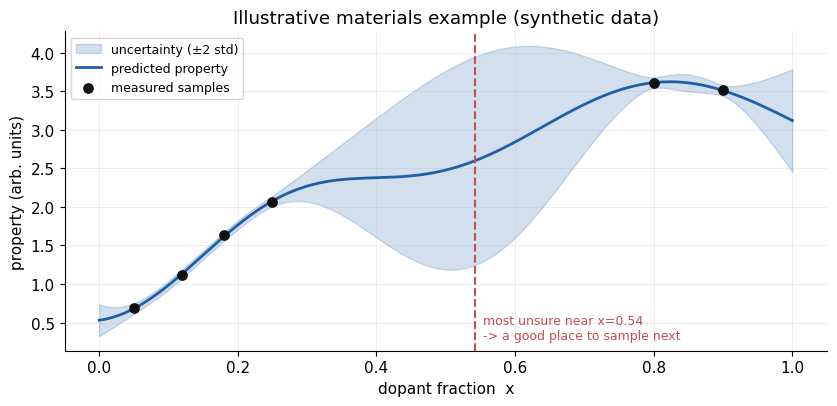

In [6]:
# ILLUSTRATIVE synthetic materials example (all numbers are made up)
x_meas = np.array([0.05, 0.12, 0.18, 0.25, 0.80, 0.90]).reshape(-1, 1)
true_property = lambda x: 2.0 + 2.5*x - 6.0*(x - 0.55)**2
y_meas = true_property(x_meas).ravel() + 0.03*np.random.default_rng(3).standard_normal(len(x_meas))

gp = GaussianProcessRegressor(kernel=C(1.0)*RBF(0.2), alpha=1e-3,
                              normalize_y=True, optimizer=None)
gp.fit(x_meas, y_meas)
xx = np.linspace(0, 1, 300).reshape(-1, 1)
m, s = gp.predict(xx, return_std=True)
x_star = float(xx[np.argmax(s)][0])          # where the model is least sure

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.fill_between(xx.ravel(), m-2*s, m+2*s, color=BAND_C, alpha=0.20,
                label="uncertainty (\u00b12 std)")
ax.plot(xx, m, color=MEAN_C, lw=2, label="predicted property")
ax.scatter(x_meas, y_meas, color=DATA_C, zorder=5, s=45, label="measured samples")
ax.axvline(x_star, color=TRUE_C, ls="--", lw=1.5)
ax.text(x_star+0.012, ax.get_ylim()[0]+0.15,
        f"most unsure near x={x_star:.2f}\n-> a good place to sample next",
        color=TRUE_C, fontsize=9)
ax.set_xlabel("dopant fraction  x"); ax.set_ylabel("property (arb. units)")
ax.set_title("Illustrative materials example (synthetic data)")
ax.legend(loc="upper left", fontsize=9); plt.tight_layout(); plt.show()


The widest part of the band is a message: *"This is where I know the least."* If your next experiment is expensive, that is often exactly where it is most worth running - you learn the most there.

Using a model's uncertainty to pick the next experiment is the heart of **Bayesian Optimization**. GPR is the engine that makes it possible.

:::{warning} Honest limitations
GPR is not magic:
- It gets **slow on large datasets** (the cost grows fast with the number of points), so it suits small-to-medium data.
- Its predictions are only as good as the **kernel** you choose. A poor kernel gives poor uncertainty.
- Far from all data, it simply falls back to its prior belief.
:::

## Putting it together

- Older regression gives **one answer**. GPR gives **an answer plus honest doubt**.
- A Gaussian Process is a tidy way to hold a **whole cloud of smooth curves** at once.
- **Prior** = the cloud before data. **Posterior** = the cloud pinched to fit the data.
- Uncertainty is **small near data** and **large far from it**. Exactly what we wanted.
- The **kernel** (and its length-scale) sets how smooth the curves are and how far trends are trusted; scikit-learn can tune it for you.
- In code, the magic flag is **`return_std=True`**.
- This honest uncertainty is what powers **Bayesian Optimization** - smart choosing of the next experiment.

**GPR does not just predict - it tells you how much to trust the prediction.**

## Check your understanding

:::{dropdown} 1. Two models both predict 250 HV for a new alloy. One is a Lasso model, the other a GPR. What can the GPR tell you that the Lasso cannot?
The GPR also gives an **uncertainty** - an error bar around the 250 HV. It can say whether 250 is a confident prediction (thin band) or a shaky guess (wide band). The Lasso just gives the number.
:::

:::{dropdown} 2. On a GPR plot, where is the shaded band narrowest, and where is it widest?
**Narrowest** right at the training data points (the "nails"). **Widest** in gaps between points and, especially, far beyond the last data point (extrapolation).
:::

:::{dropdown} 3. You increase the kernel's length-scale. What happens to the fitted curve?
It becomes **smoother**, and the model stays **confident over wider gaps**. A very long length-scale can smooth over real detail; a very short one makes the curve wiggly and unsure almost everywhere except right at the data.
:::

:::{dropdown} 4. Which single piece of scikit-learn code turns a plain prediction into GPR's special feature?
`mean, std = gpr.predict(X, return_std=True)` - the `return_std=True` flag returns the uncertainty alongside the prediction.
:::

:::{dropdown} 5. Why is GPR an especially good fit for experimental materials datasets?
They are usually **small and expensive**. GPR handles small data well and, crucially, its uncertainty tells you **where to run the next experiment** to learn the most.
:::

:::{dropdown} For the curious: a peek at the maths (optional)
You can skip this and still use GPR well.

A Gaussian Process says: for *any* set of input points, the function values follow one big **multivariate Normal distribution**. Its shape is set by a **mean function** (usually taken as 0 after centering) and a **kernel** $k(x, x')$ that says how correlated two points are.

A very common kernel is the **squared-exponential (RBF)**:

$$
k(x, x') = \sigma^2 \exp\!\left( -\frac{(x - x')^2}{2\,\ell^{2}} \right)
$$

where $\ell$ is the **length-scale** and $\sigma^2$ the overall variance.

Given training inputs with values $\mathbf{y}$, the prediction at new points $X_*$ has a closed form:

$$
\text{mean} = K_{*}\,\left(K + \sigma_n^2 I\right)^{-1}\mathbf{y}
$$

$$
\text{variance} = K_{**} - K_{*}\left(K + \sigma_n^2 I\right)^{-1}K_{*}^{\top}
$$

Here $K$ is the kernel between training points, $K_*$ between test and training points, $K_{**}$ between test points, and $\sigma_n^2$ a small noise term. Those two lines are exactly the **mean curve** and the **uncertainty band** you saw in the pictures - no simulation needed, just linear algebra.

The kernel settings ($\ell$, $\sigma$, noise) are chosen by maximizing the **log marginal likelihood** - a score for how well the whole setup explains the data. That is what `scikit-learn` does inside `.fit()`.
:::

:::{seealso} Where to read more
- Rasmussen, C. E. & Williams, C. K. I. (2006). *Gaussian Processes for Machine Learning.* MIT Press. The standard reference - and it is **free to read online** at [gaussianprocess.org/gpml](https://gaussianprocess.org/gpml/).
- The scikit-learn User Guide section on *Gaussian Processes* has practical `GaussianProcessRegressor` examples.
:::

:::{admonition} Coming up
:class: tip
Next we put GPR's uncertainty to work: **Bayesian Optimization** - a smart loop that keeps asking *"given what I know, and how unsure I am, which experiment should I run next?"* GPR is the engine inside it.
:::